<a href="https://colab.research.google.com/github/dmhenaopa/EDCO/blob/main/Proyectos/climate_model.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Análisis exploratorio de datos (EDA)

Pregunta de investigación: ¿Cuánto aumentará la temperatura global en los próximos años (por ejemplo, 2026–2030) si el CO₂ sigue su tendencia actual?

In [9]:
from google.colab import drive
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from pathlib import Path
from IPython.display import display
from scipy import stats

from sklearn.model_selection import train_test_split, KFold, cross_validate
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder
from sklearn.linear_model import LinearRegression
from sklearn.dummy import DummyRegressor
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error

# Montar Google Drive para acceder a los datos
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


Datos:
1. year:	Año
2. temp_anom:	Anomalía de temperatura anual en °C respecto a 1951–1980.
3. co2_ppm:	CO₂ promedio del año en ppm

In [10]:
# Definir la ruta al archivo en Drive
ruta = '/content/drive/MyDrive/EDCO_IntroCienciaDatos/Proyectos/dataset_anual.csv'

# Carga de datos:
df = pd.read_csv(ruta)

display(df.head())

,year,temp_anom,co2_ppm,oni,oni_lag1,ln_co2
0,1959,0.03,315.98,0.199167,0.716667,0.120889
1,1960,-0.02,316.91,0.050833,0.199167,0.123828
2,1961,0.06,317.64,-0.024167,0.050833,0.126129
3,1962,0.03,318.45,-0.173333,-0.024167,0.128676
4,1963,0.05,318.99,0.550000,-0.173333,0.130370


In [4]:
# Número de columnas y registros
print(f"Observaciones: {df.shape[0]} | Columnas: {df.shape[1]}")

Observaciones: 67 | Columnas: 6


In [5]:
# Verificación de los tipos de las columnas
display(df.dtypes.to_frame("Tipo"))

,Tipo
year,int64
temp_anom,float64
co2_ppm,float64
oni,float64
oni_lag1,float64
ln_co2,float64


### Calidad de los datos

,tipo,faltantes,% faltante,distintos
year,int64,0,0.0,67
temp_anom,float64,0,0.0,49
co2_ppm,float64,0,0.0,67
oni,float64,0,0.0,67
oni_lag1,float64,0,0.0,67
ln_co2,float64,0,0.0,67


Filas duplicadas exactamente: 0


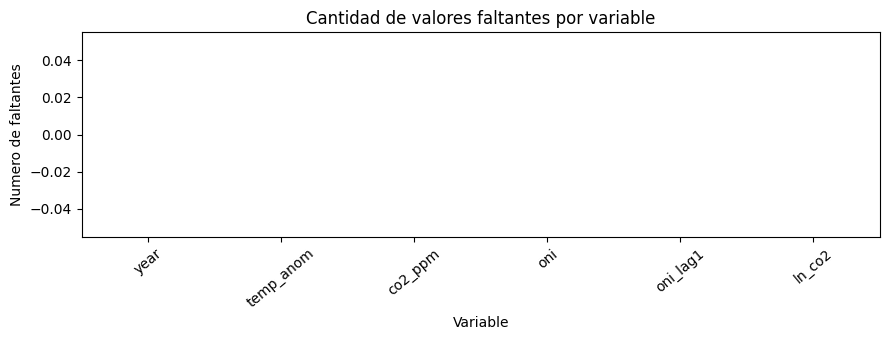

In [11]:
resumen_calidad = pd.DataFrame({
    "tipo": df.dtypes.astype(str),
    "faltantes": df.isna().sum(),
    "% faltante": (100 * df.isna().mean()).round(2),
    "distintos": df.nunique(dropna=True)
}).sort_values("faltantes", ascending=False)

display(resumen_calidad)
print("Filas duplicadas exactamente:", df.duplicated().sum())

fig, ax = plt.subplots(figsize=(9, 3.5))
faltantes = df.isna().sum().sort_values(ascending=False)
sns.barplot(x=faltantes.index, y=faltantes.values, ax=ax, color="steelblue")
ax.set(title="Cantidad de valores faltantes por variable", xlabel="Variable", ylabel="Numero de faltantes")
ax.tick_params(axis="x", rotation=40)
plt.tight_layout()
plt.show()

# Separar entrenamiento y prueba

In [14]:
entrenamiento, prueba = train_test_split(df, test_size=0.20, random_state=42)
eda = entrenamiento.copy()

print("Entrenamiento (para EDA y seleccion de modelo):", len(entrenamiento))
print("Prueba (reservado hasta el final):", len(prueba))
print("Porcentaje reservado para prueba:", round(100 * len(prueba) / len(df), 1), "%")

Entrenamiento (para EDA y seleccion de modelo): 53
Prueba (reservado hasta el final): 14
Porcentaje reservado para prueba: 20.9 %


### Estadistica descriptiva

,count,mean,std,min,25%,50%,75%,max
year,53.0,1993.09,18.74,1960.00,1978.00,1993.00,2009.00,2025.00
temp_anom,53.0,0.42,0.35,-0.11,0.14,0.39,0.66,1.28
co2_ppm,53.0,362.70,31.86,316.91,335.41,357.21,387.64,427.35


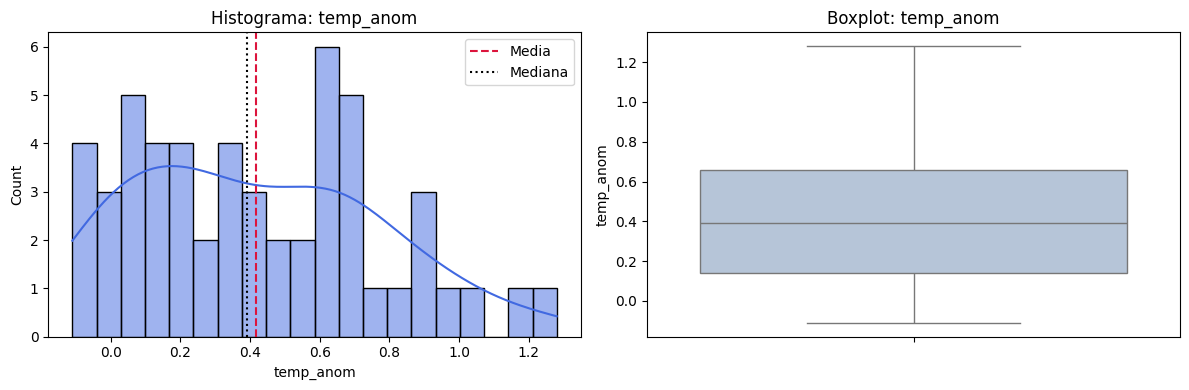

In [21]:
variables = ["year", "temp_anom", "co2_ppm"]
display(eda[variables].describe().T.round(2))

fig, axs = plt.subplots(1, 2, figsize=(12, 4))
sns.histplot(data=eda, x="temp_anom", bins=20, kde=True, ax=axs[0], color="royalblue")
axs[0].axvline(eda["temp_anom"].mean(), ls="--", c="crimson", label="Media")
axs[0].axvline(eda["temp_anom"].median(), ls=":", c="black", label="Mediana")
axs[0].set(title="Histograma: temp_anom", xlabel="temp_anom")
axs[0].legend()
sns.boxplot(y=eda["temp_anom"], ax=axs[1], color="lightsteelblue")
axs[1].set(title="Boxplot: temp_anom", ylabel="temp_anom")
plt.tight_layout()
plt.show()

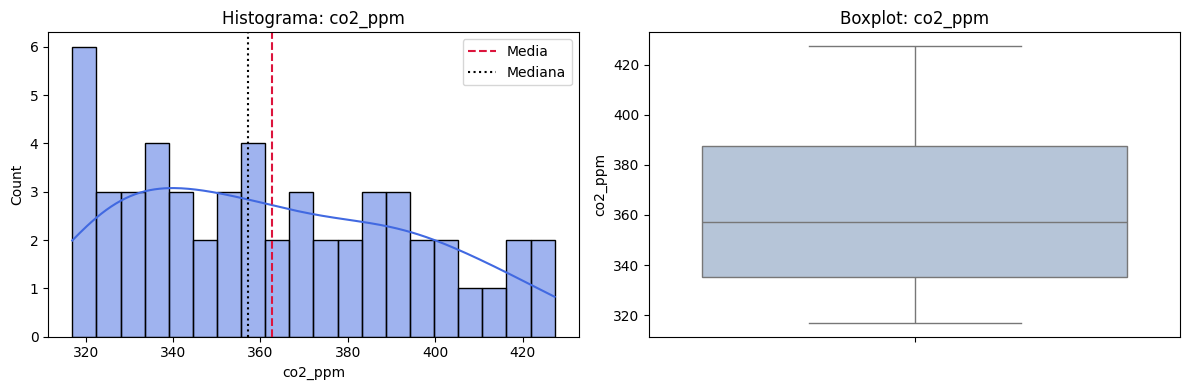

In [22]:
fig, axs = plt.subplots(1, 2, figsize=(12, 4))
sns.histplot(data=eda, x="co2_ppm", bins=20, kde=True, ax=axs[0], color="royalblue")
axs[0].axvline(eda["co2_ppm"].mean(), ls="--", c="crimson", label="Media")
axs[0].axvline(eda["co2_ppm"].median(), ls=":", c="black", label="Mediana")
axs[0].set(title="Histograma: co2_ppm", xlabel="co2_ppm")
axs[0].legend()
sns.boxplot(y=eda["co2_ppm"], ax=axs[1], color="lightsteelblue")
axs[1].set(title="Boxplot: co2_ppm", ylabel="co2_ppm")
plt.tight_layout()
plt.show()